# Predicción de abandono de clientes
La regresión logística estima si un cliente de telecomunicaciones abandonará el servicio. En este ejercicio, `Churn = Yes` es la clase positiva.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

Matplotlib is building the font cache; this may take a moment.


## Carga y preparación

In [2]:
data_path = Path("data") / "Telco-Customer-Churn.csv"
customers = pd.read_csv(data_path)
customers["TotalCharges"] = pd.to_numeric(customers["TotalCharges"], errors="coerce")
X = customers.drop(columns=["customerID", "Churn"])
y = customers["Churn"].map({"No": 0, "Yes": 1})

print(f"Clientes: {len(customers):,} | Tasa de abandono: {y.mean():.1%}")
display(X.head())

Clientes: 7,043 | Tasa de abandono: 26.5%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


## División de datos 80/20
Usamos una división estratificada para mantener la proporción de churn en ambos conjuntos.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
split_summary = pd.DataFrame(
    {
        "Dimensiones de X": [str(X_train.shape), str(X_test.shape)],
        "Dimensiones de y": [str(y_train.shape), str(y_test.shape)],
        "Porcentaje del total": [f"{len(y_train) / len(y):.2%}", f"{len(y_test) / len(y):.2%}"],
        "Tasa de churn": [f"{y_train.mean():.2%}", f"{y_test.mean():.2%}"],
    },
    index=["Entrenamiento", "Prueba"],
)
display(split_summary)

,Dimensiones de X,Dimensiones de y,Porcentaje del total,Tasa de churn
Entrenamiento,"(5634, 19)","(5634,)",79.99%,26.54%
Prueba,"(1409, 19)","(1409,)",20.01%,26.54%


## Entrenamiento del modelo
La regresión logística y su preprocesamiento se ajustan usando solo el conjunto de entrenamiento.

In [4]:
numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.columns.difference(numeric_columns)

numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessing = ColumnTransformer([
    ("numeric", numeric_steps, numeric_columns),
    ("categorical", categorical_steps, categorical_columns),
])

model = Pipeline([
    ("preprocessing", preprocessing),
    ("classifier", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(f"Regresión logística entrenada con {len(X_train):,} clientes. Predicciones de prueba: {len(predictions):,}.")

Regresión logística entrenada con 5,634 clientes. Predicciones de prueba: 1,409.


## Métricas de prueba
Las cuatro métricas se calculan con las predicciones del conjunto de prueba. La clase positiva es abandono.

In [5]:
metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, zero_division=0),
    "Recall": recall_score(y_test, predictions, zero_division=0),
    "F1-Score": f1_score(y_test, predictions, zero_division=0),
}, name="Resultado")
display(metrics.round(4).to_frame())

,Resultado
Accuracy,0.8055
Precision,0.6572
Recall,0.5588
F1-Score,0.6040


## Matriz de confusión
Las filas representan las clases reales y las columnas, las clases predichas.

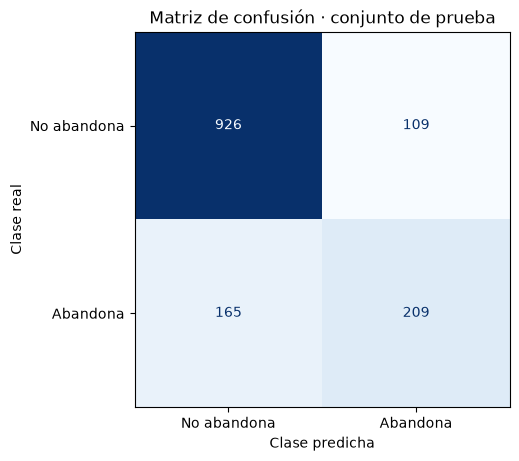

Abandonos detectados: 209 de 374 | Falsos negativos: 165 | Falsos positivos: 109


In [6]:
counts = confusion_matrix(y_test, predictions, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
ConfusionMatrixDisplay(
    confusion_matrix=counts,
    display_labels=["No abandona", "Abandona"],
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set(xlabel="Clase predicha", ylabel="Clase real", title="Matriz de confusión · conjunto de prueba")
plt.show()

tn, fp, fn, tp = counts.ravel()
print(f"Abandonos detectados: {tp} de {tp + fn} | Falsos negativos: {fn} | Falsos positivos: {fp}")

## Interpretación de negocio
**Recall** es la métrica prioritaria si perder un cliente cuesta más que realizar un contacto de retención innecesario. Mide qué proporción de quienes realmente abandonan queda identificada. Un falso negativo es un cliente que abandona y al que el modelo no alerta. La empresa pierde la oportunidad de intervenir y puede perder ingresos futuros de ese cliente.

**Precision** mide qué proporción de las alertas corresponde a abandonos reales. Los falsos positivos pueden consumir tiempo del equipo de retención o descuentos. **F1** resume el equilibrio entre precision y recall, mientras que **accuracy** mide el acierto global y puede ocultar abandonos omitidos porque la mayoría de los clientes permanece.

**Resultado de prueba.** El modelo acertó el 80,55 % de las predicciones y detectó 209 de 374 abandonos (recall del 55,88 %). Los 165 falsos negativos, el 44,12 % de los abandonos reales, representan clientes que quedarían fuera de una campaña basada en estas alertas. También hubo 109 falsos positivos. Si los costos de perder clientes justifican más contactos, se podría evaluar un umbral menor en un conjunto de validación para detectar más abandonos y medir cuántas alertas adicionales generaría.